Imports and loading

In [28]:
# pandas for data handling, numpy for math
import pandas as pd
import numpy as np

# matplotlib and seaborn for drawing charts
import matplotlib.pyplot as plt
import seaborn as sns

# Show all columns when printing tables
pd.set_option("display.max_columns",None)

# Make charts look cleaner and set a default size
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8,5)


In [29]:
# Load the dataset
df = pd.read_csv("../data/creditcard.csv")

print("Shape:",df.shape)

Shape: (284807, 31)


Basic statistics

In [30]:
# describe() gives count, mean, std, min, max and quartiles for each numeric column
# .T flips the table (rows <-> columns) so its's easier to read with 31 columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [31]:
# duplicated() marks rows that are exact copies of an earlier row; sum() counts them
dup_count = df.duplicated().sum()
print("Duplicated rows", dup_count)

Duplicated rows 1081


Visualize the class imbalance

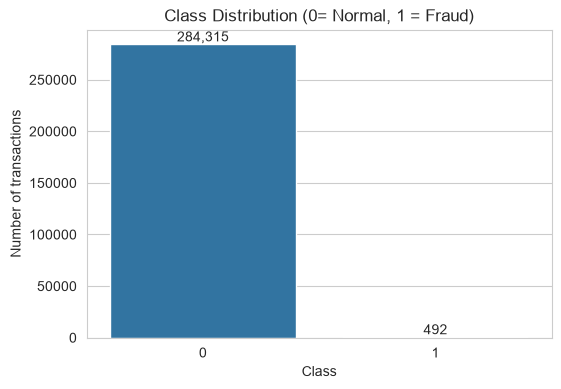

In [32]:
# Count how many normal (0) and fraud (1) transcation we have
class_counts = df["Class"].value_counts()

# Draw a bar chart of the counts
plt.figure(figsize=(6,4))
sns.barplot(x=class_counts.index,y=class_counts.values)

plt.title("Class Distribution (0= Normal, 1 = Fraud)")
plt.xlabel("Class")
plt.ylabel("Number of transactions")

# Write the exact count on top of each bar
for i, value in enumerate(class_counts.values):
    plt.text(i, value,f"{value:,}", ha="center", va="bottom")

plt.show()

Analyze the Amount column

In [33]:
# Split the data into two groups so we can compare them
normal = df[df["Class"] == 0] # only normal transactions
fraud = df[df["Class"] == 1] # only fraud transactions

# Compare the Amount statistics of the two groups side by side
print("Normal transactions - Amount:")
print(normal["Amount"].describe())

print("\nFraud transactions - Amount:")
print(fraud["Amount"].describe())

Normal transactions - Amount:
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

Fraud transactions - Amount:
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


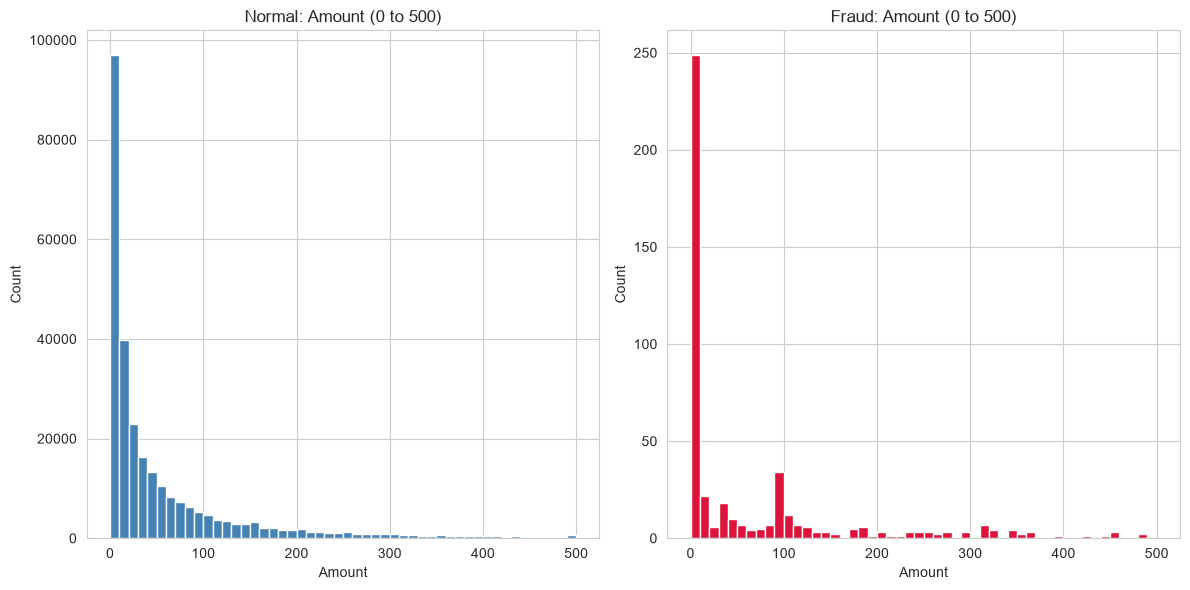

In [34]:
# Draw two histograms side by side to compare Amount distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Left chart: normal transactions (cap at 500 so the chart is readable)
axes[0].hist(normal["Amount"], bins=50, range=(0, 500), color="steelblue")
axes[0].set_title("Normal: Amount (0 to 500)")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Count")

# Right chart: fraud transactions
axes[1].hist(fraud["Amount"], bins=50, range=(0, 500), color="crimson")
axes[1].set_title("Fraud: Amount (0 to 500)")
axes[1].set_xlabel("Amount")
axes[1].set_ylabel("Count")

plt.tight_layout()   # stops the charts from overlapping
plt.show()

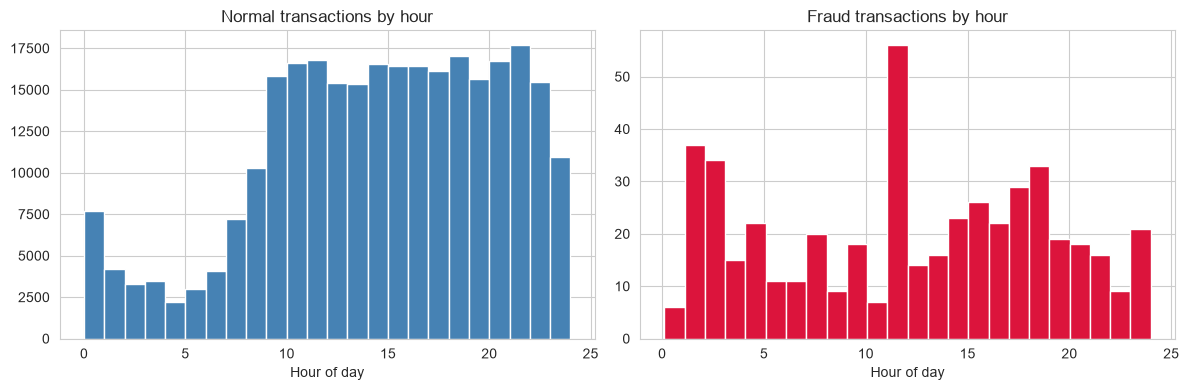

In [35]:
# Time is in seconds since the first transaction. Convert to hours for readability.
df["Hour"] = (df["Time"] / 3600) % 24    # % 24 wraps it into a 24-hour clock (data covers 2 days)

# Plot how many transactions happen at each hour, for each class
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df[df["Class"] == 0]["Hour"], bins=24, color="steelblue")
axes[0].set_title("Normal transactions by hour")
axes[0].set_xlabel("Hour of day")

axes[1].hist(df[df["Class"] == 1]["Hour"], bins=24, color="crimson")
axes[1].set_title("Fraud transactions by hour")
axes[1].set_xlabel("Hour of day")

plt.tight_layout()
plt.show()

# Remove the temporary Hour column; we only used it for this chart
df = df.drop(columns=["Hour"])

Which features separate fraud from normal?

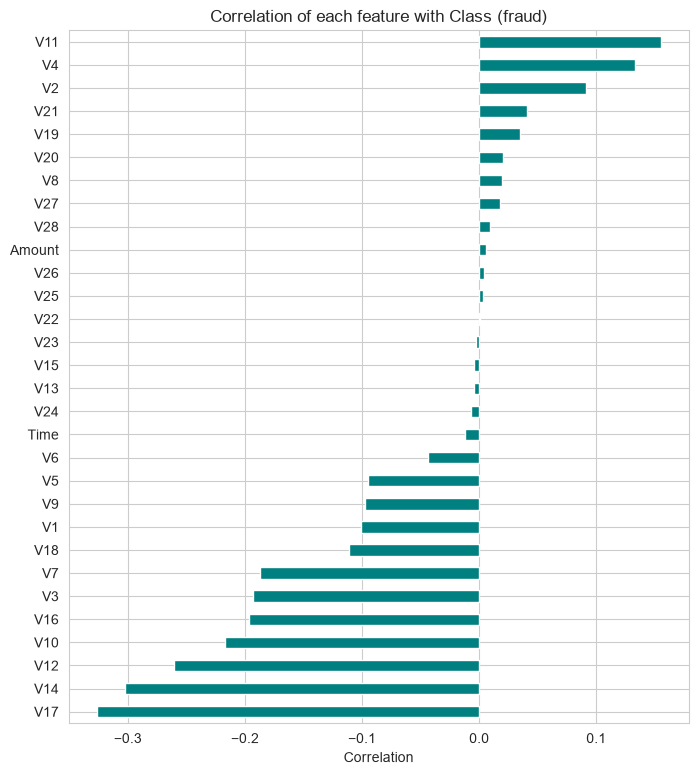

Most negatively correlated with fraud:
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64

Most positively correlated with fraud:
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
Name: Class, dtype: float64


In [36]:
# Correlation of every column with the target "Class"
# corr() measures the linear relationship (-1 to +1) between columns
correlations = df.corr()["Class"].drop("Class").sort_values()

# Draw a horizontal bar chart of the correlations
plt.figure(figsize=(8, 9))
correlations.plot(kind="barh", color="teal")
plt.title("Correlation of each feature with Class (fraud)")
plt.xlabel("Correlation")
plt.show()

# Print the top 5 positive and top 5 negative correlations
print("Most negatively correlated with fraud:")
print(correlations.head(5))
print("\nMost positively correlated with fraud:")
print(correlations.tail(5))

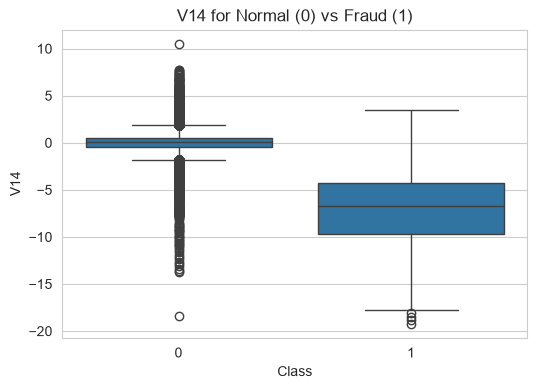

In [37]:
# A boxplot shows the median, spread and outliers of V14 for each class
plt.figure(figsize=(6,4))
sns.boxplot(x="Class", y="V14", data=df)
plt.title("V14 for Normal (0) vs Fraud (1)")
plt.show()

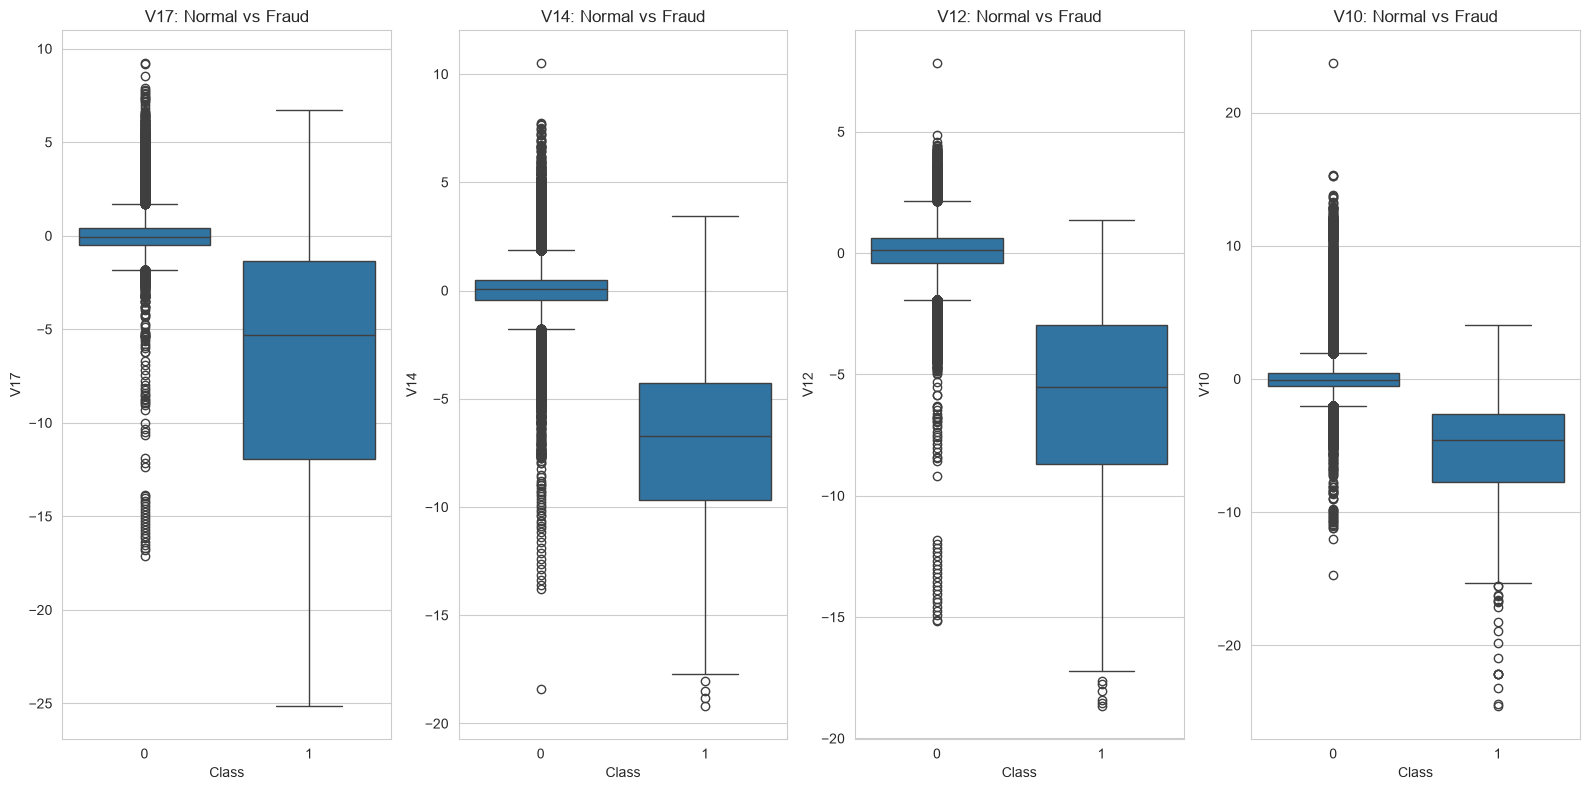

In [41]:
# The features with the strongest correlation to fraud (from our correlation chart)
top_features = ["V17", "V14", "V12", "V10"]

# Create a 1-row, 4-column grid of charts
fig, axes = plt.subplots(1, 4, figsize=(16, 8))

# Loop over each feature and its matching chart position
for ax, feature in zip(axes, top_features):
    # Boxplot of this feature for Normal (0) vs Fraud (1)
    sns.boxplot(x="Class", y=feature, data=df, ax=ax)
    ax.set_title(f"{feature}: Normal vs Fraud")

plt.tight_layout()   # stops the charts from overlapping
plt.show()